# 03 · Fine-tuning Experiments (run on Google Colab GPU)

In this notebook I fine-tune and evaluate all my models. I ran it on Google Colab with a GPU (an NVIDIA A100 for this run).

All results and model weights are saved to my Google Drive. If the Colab session disconnects, I can run the notebook again: experiments that already have a `metrics.json` file are skipped, and only the missing ones are trained.

I organised the experiments by priority:

| Priority | Experiments | Question |
|---|---|---|
| 1 | zero-shot Qwen 0.5B, LoRA Qwen 0.5B, Flan-T5 full fine-tuning, LoRA + RAG | Does fine-tuning help, which architecture works better, and does retrieval help? |
| 2 | LoRA rank 8/32, lower learning rate, attention-only LoRA, clean data, zero-shot + RAG | Which settings matter? |
| 3 | zero-shot and LoRA Qwen 1.5B, with and without RAG | Does a larger base model help? |

In [1]:
!nvidia-smi

Tue Oct 13 09:24:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   33C    P0             43W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [2]:
GITHUB_REPO = "https://github.com/mukunzindahiro-max/afrimed-assistant.git"
!git clone -q $GITHUB_REPO /content/afrimed-assistant || (cd /content/afrimed-assistant && git pull -q)
%cd /content/afrimed-assistant
!pip install -q -r requirements.txt

/content/afrimed-assistant
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 4.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 137.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.7/320.7 kB 32.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 333.2/333.2 kB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 480.6/480.6 kB 45.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 255.8/255.8 kB 27.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 50.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.3/32.3 MB 84.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/6

I clone my GitHub repository into Colab and install the exact library versions from `requirements.txt`, so the code runs the same way as on my laptop.

In [3]:
from google.colab import drive, userdata
import os
drive.mount("/content/drive")
DRIVE = "/content/drive/MyDrive/afrimed-assistant"
os.makedirs(f"{DRIVE}/results", exist_ok=True)
os.makedirs(f"{DRIVE}/models", exist_ok=True)
!cp -rn results/. $DRIVE/results/ && rm -rf results models && ln -s $DRIVE/results results && ln -s $DRIVE/models models
!ls results results/ood
os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
from huggingface_hub import login
login(token=os.environ["HF_TOKEN"])

Mounted at /content/drive
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
results:
baseline_majority   baseline_random  ood
baseline_minilm_nn  baseline_tfidf   zs_qwen05

results/ood:
metrics.json  probe_questions.jsonl  test_scores.csv  val_scores.csv


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


I mount Google Drive and replace the `results` and `models` folders with links to Drive, so everything the experiments write is saved permanently. The baseline results from notebook 02 are copied first. I log in to Hugging Face with a token stored in Colab secrets, so the token never appears in the notebook.

In [5]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
!sed -i 's/^  batch_size: 8$/  batch_size: 4/; s/^  grad_accum: 2$/  grad_accum: 4/' configs/experiments.yaml
!grep -nE "^  (batch_size|grad_accum):" configs/experiments.yaml
import warnings
warnings.filterwarnings("ignore")
from huggingface_hub.utils import disable_progress_bars
disable_progress_bars()
import datasets
datasets.disable_progress_bars()

10:  batch_size: 4
11:  grad_accum: 4


I use a batch size of 4 with 4 gradient-accumulation steps, which keeps the effective batch size at 16. I first tried a batch size of 8 on a T4 GPU and it ran out of memory, because Qwen has a vocabulary of about 151k tokens and the output layer is very large. I kept 4 x 4 for every run so all experiments use the same setting. I also hide library warnings and download progress bars to keep the output readable.

In [6]:
import sys, json
from pathlib import Path
ROOT = Path("/content/afrimed-assistant")
sys.path.insert(0, str(ROOT / "src"))
import os
os.environ.setdefault("AFRIMED_ROOT", str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

In [7]:
from afrimed.data import prepare
_, sup, unlabeled, report = prepare()
print(json.dumps(report["split_counts"], indent=1))

{
 "test": {
  "consumer_queries": 0,
  "mcq": 808,
  "saq": 246
 },
 "train": {
  "consumer_queries": 118,
  "mcq": 2816,
  "saq": 849
 },
 "val": {
  "consumer_queries": 14,
  "mcq": 404,
  "saq": 123
 }
}


I rebuild exactly the same splits as in notebook 01 (the pipeline is deterministic with a fixed seed), so the Colab experiments train and test on the same data as my local analysis.

## Model choices

**Why these models?**

* **Qwen2.5-0.5B-Instruct and 1.5B-Instruct** are decoder-only Transformers. They are already instruction-tuned, they follow a chat template, and they are small enough to fine-tune on one GPU and to run on a free CPU server for the web app.
* **LoRA** (Low-Rank Adaptation) freezes the original weights W and learns a small update, delta W = (alpha / r) x B x A, where B and A are thin matrices of rank r. With r = 16 on all linear layers, only about 1.75% of the parameters are trained. This is faster, uses less memory, and reduces the risk of overfitting on my small dataset.
* **Flan-T5-base** is an encoder-decoder Transformer. I fine-tune all of its weights as a contrast to LoRA, to see whether a different architecture with full fine-tuning does better.

**Training setup:** cosine learning-rate schedule with 5% warm-up, 2 epochs for Qwen (3 for Flan-T5), mixed precision (fp16) for Qwen, and loss computed only on the answer tokens.

**Evaluation:** for MCQs I do not let the model generate freely. I add "Answer:" after the prompt and read the probability of each letter A to E at the next token, which gives a prediction and a confidence for calibration. For SAQs the model generates an answer with greedy decoding, which I compare with the reference using ROUGE-L, BLEU, chrF, BERTScore and semantic similarity.

In [8]:
from afrimed.train import load_experiments
exps = load_experiments()
pd.DataFrame([{k: getattr(c, k) for k in ["name", "priority", "model_id", "method", "lora_r", "lora_alpha", "learning_rate", "epochs", "target_modules", "data_variant", "rag"]} for c in exps.values()])

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


,name,priority,model_id,method,lora_r,lora_alpha,learning_rate,epochs,target_modules,data_variant,rag
0,zs_qwen05,1,Qwen/Qwen2.5-0.5B-Instruct,none,16,32,0.00020,2,"[q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj]",all,False
1,lora_qwen05_r16,1,Qwen/Qwen2.5-0.5B-Instruct,lora,16,32,0.00020,2,"[q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj]",all,False
2,ft_flant5_base,1,google/flan-t5-base,full,16,32,0.00030,3,"[q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj]",all,False
3,lora_qwen05_r16_rag,1,Qwen/Qwen2.5-0.5B-Instruct,none,16,32,0.00020,2,"[q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj]",all,True
4,lora_qwen05_r8,2,Qwen/Qwen2.5-0.5B-Instruct,lora,8,16,0.00020,2,"[q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj]",all,False
5,lora_qwen05_r32,2,Qwen/Qwen2.5-0.5B-Instruct,lora,32,64,0.00020,2,"[q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj]",all,False
6,lora_qwen05_r16_lr5e5,2,Qwen/Qwen2.5-0.5B-Instruct,lora,16,32,0.00005,2,"[q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj]",all,False
7,lora_qwen05_r16_attn,2,Qwen/Qwen2.5-0.5B-Instruct,lora,16,32,0.00020,2,"[q_proj, k_proj, v_proj, o_proj]",all,False
8,lora_qwen05_r16_clean,2,Qwen/Qwen2.5-0.5B-Instruct,lora,16,32,0.00020,2,"[q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj]",clean,False
9,zs_qwen05_rag,2,Qwen/Qwen2.5-0.5B-Instruct,none,16,32,0.00020,2,"[q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj]",all,True


This table lists every experiment and its settings. Each experiment changes one thing compared to my main model (`lora_qwen05_r16`), so I can see the effect of that one change.

In [9]:
METRIC_COLS = ["mcq_accuracy", "mcq_macro_f1", "mcq_ece", "mcq_multi_exact_match", "mcq_multi_jaccard",
               "saq_rougeL", "saq_token_f1", "saq_semantic_sim", "saq_bertscore_f1", "saq_bleu", "saq_chrf",
               "saq_avg_pred_words", "saq_avg_ref_words"]


def show_runs(names):
    for name in names:
        run_dir = ROOT / "results" / name
        display(Markdown(f"### `{name}`"))
        log_path = run_dir / "train_log.json"
        if log_path.exists():
            log = json.loads(log_path.read_text())
            hist = pd.DataFrame(log["log_history"])
            train_loss = hist.dropna(subset=["loss"]).set_index("step")["loss"]
            evals = hist.dropna(subset=["eval_loss"]).drop_duplicates("step").set_index("step")["eval_loss"]
            table = pd.DataFrame({"training_loss": train_loss.reindex(evals.index, method="ffill"),
                                  "validation_loss": evals})
            table.index.name = "step"
            params = log["params"]
            print(f"trainable params: {params['trainable_params']:,} of {params['total_params']:,} "
                  f"({params['trainable_pct']:.2f}%) | train examples: {log['n_train']} | "
                  f"training time: {log['train_time_sec'] / 60:.1f} min | final val loss: {log['final_val_loss']:.4f}")
            display(table.round(4))
        else:
            print("no training (evaluated as-is)")
        metrics = json.loads((run_dir / "metrics.json").read_text())
        display(pd.DataFrame([{k: metrics.get(k) for k in METRIC_COLS}], index=[name]).round(4))

`show_runs` reads the saved files of each experiment and prints a short report: the number of trainable parameters, the training time, a table of training and validation loss at each evaluation step, and the test metrics.

## Priority 1: core experiments

First I run the zero-shot baseline (Qwen 0.5B with no training) and my main LoRA model. Comparing the two shows how much fine-tuning on AfriMed-QA adds.

In [10]:
from afrimed.experiments import run_all
_ = run_all(names=["zs_qwen05", "lora_qwen05_r16"])

[run] zs_qwen05: Qwen2.5-0.5B-Instruct without fine-tuning


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{
  "name": "zs_qwen05",
  "group": "zero-shot",
  "description": "Qwen2.5-0.5B-Instruct without fine-tuning",
  "model_id": "Qwen/Qwen2.5-0.5B-Instruct",
  "method": "none",
  "rag": false,
  "mcq_accuracy": 0.3257372654155496,
  "mcq_macro_f1": 0.31217043763588,
  "mcq_ece": 0.27405426617282325,
  "mcq_n": 746,
  "mcq_multi_exact_match": 0.0,
  "mcq_multi_jaccard": 0.04247311827956989,
  "mcq_multi_n": 62,
  "saq_rougeL": 0.18176860508649892,
  "saq_token_f1": 0.2087870405349147,
  "saq_semantic_sim": 0.6919621825218201,
  "saq_bertscore_f1": 0.11599505692720413,
  "saq_bleu": 5.31685742989497,
  "saq_chrf": 35.34246924010201,
  "saq_avg_pred_words": 81.23577235772358,
  "saq_avg_ref_words": 38.0650406504065,
  "saq_n": 246,
  "eval_time_sec": 97.22757506370544
}
[run] lora_qwen05_r16: Qwen2.5-0.5B-Instruct + LoRA (r=16, all linear layers, lr=2e-4, 2 epochs)


Step,Training Loss,Validation Loss
59,1.081600,0.738652
118,1.091200,0.724058
177,0.982000,0.699733
236,1.173800,0.684724
295,0.666000,0.689183
354,0.718700,0.694081
413,0.803500,0.692288
472,0.796800,0.692087


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{
  "name": "lora_qwen05_r16",
  "group": "lora",
  "description": "Qwen2.5-0.5B-Instruct + LoRA (r=16, all linear layers, lr=2e-4, 2 epochs)",
  "model_id": "Qwen/Qwen2.5-0.5B-Instruct",
  "method": "lora",
  "rag": false,
  "mcq_accuracy": 0.3739946380697051,
  "mcq_macro_f1": 0.3640913395857626,
  "mcq_ece": 0.13433912436380466,
  "mcq_n": 746,
  "mcq_multi_exact_match": 0.04838709677419355,
  "mcq_multi_jaccard": 0.4271505376344086,
  "mcq_multi_n": 62,
  "saq_rougeL": 0.3087917497634657,
  "saq_token_f1": 0.31965058015087205,
  "saq_semantic_sim": 0.6751220226287842,
  "saq_bertscore_f1": 0.30121681094169617,
  "saq_bleu": 13.953666209030029,
  "saq_chrf": 35.015367900508444,
  "saq_avg_pred_words": 31.963414634146343,
  "saq_avg_ref_words": 38.0650406504065,
  "saq_n": 246,
  "eval_time_sec": 66.67370963096619
}


Before Flan-T5, I clear an environment variable. The Hugging Face `Trainer` sets `ACCELERATE_MIXED_PRECISION=fp16` during the fp16 Qwen run and never resets it. Without this line, Flan-T5 silently trained in fp16 too, its values overflowed, and the loss became NaN. I found this because the logged learning rate stayed at 0 and the validation loss was NaN.

In [11]:
os.environ.pop("ACCELERATE_MIXED_PRECISION", None)
_ = run_all(names=["ft_flant5_base", "lora_qwen05_r16_rag"])

[run] ft_flant5_base: Flan-T5-base encoder-decoder, full fine-tuning


Passing a tuple of `past_key_values` is deprecated and will be removed in Transformers v4.48.0. You should pass an instance of `EncoderDecoderCache` instead, e.g. `past_key_values=EncoderDecoderCache.from_legacy_cache(past_key_values)`.


Step,Training Loss,Validation Loss
59,1.340500,0.961096
118,1.408900,0.933560
177,1.440200,0.914179
236,1.405900,0.895620
295,1.079100,0.885009
354,0.979800,0.877924
413,1.218200,0.872790
472,1.111700,0.861893
531,0.699700,0.870462
590,1.005300,0.867789


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{
  "name": "ft_flant5_base",
  "group": "full-ft",
  "description": "Flan-T5-base encoder-decoder, full fine-tuning",
  "model_id": "google/flan-t5-base",
  "method": "full",
  "rag": false,
  "mcq_accuracy": 0.28820375335120646,
  "mcq_macro_f1": 0.2675450706276394,
  "mcq_ece": 0.023457877837301255,
  "mcq_n": 746,
  "mcq_multi_exact_match": 0.0,
  "mcq_multi_jaccard": 0.4043010752688172,
  "mcq_multi_n": 62,
  "saq_rougeL": 0.2928642588974631,
  "saq_token_f1": 0.3010601732849375,
  "saq_semantic_sim": 0.6215595006942749,
  "saq_bertscore_f1": 0.19715403020381927,
  "saq_bleu": 12.885524100798355,
  "saq_chrf": 29.381204710676762,
  "saq_avg_pred_words": 29.723577235772357,
  "saq_avg_ref_words": 38.0650406504065,
  "saq_n": 246,
  "eval_time_sec": 33.634395122528076
}
[run] lora_qwen05_r16_rag: LoRA r=16 model + top-3 retrieved training QA pairs as context


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{
  "name": "lora_qwen05_r16_rag",
  "group": "rag",
  "description": "LoRA r=16 model + top-3 retrieved training QA pairs as context",
  "model_id": "Qwen/Qwen2.5-0.5B-Instruct",
  "method": "none",
  "rag": true,
  "mcq_accuracy": 0.403485254691689,
  "mcq_macro_f1": 0.3885663007427325,
  "mcq_ece": 0.10033578159981694,
  "mcq_n": 746,
  "mcq_multi_exact_match": 0.016129032258064516,
  "mcq_multi_jaccard": 0.2720430107526881,
  "mcq_multi_n": 62,
  "saq_rougeL": 0.31768929360498277,
  "saq_token_f1": 0.3352383916135555,
  "saq_semantic_sim": 0.6907937526702881,
  "saq_bertscore_f1": 0.3140190541744232,
  "saq_bleu": 16.782108020377215,
  "saq_chrf": 38.70322916356097,
  "saq_avg_pred_words": 36.10569105691057,
  "saq_avg_ref_words": 38.0650406504065,
  "saq_n": 246,
  "eval_time_sec": 72.00909352302551
}


In [12]:
show_runs(["zs_qwen05", "lora_qwen05_r16", "ft_flant5_base", "lora_qwen05_r16_rag"])

### `zs_qwen05`

no training (evaluated as-is)


,mcq_accuracy,mcq_macro_f1,mcq_ece,mcq_multi_exact_match,mcq_multi_jaccard,saq_rougeL,saq_token_f1,saq_semantic_sim,saq_bertscore_f1,saq_bleu,saq_chrf,saq_avg_pred_words,saq_avg_ref_words
zs_qwen05,0.3257,0.3122,0.2741,0.0,0.0425,0.1818,0.2088,0.692,0.116,5.3169,35.3425,81.2358,38.065


### `lora_qwen05_r16`

trainable params: 8,798,208 of 502,830,976 (1.75%) | train examples: 3783 | training time: 8.8 min | final val loss: 0.6921


...

,training_loss,validation_loss
step,,
59,1.3405,0.9611
118,1.4089,0.9336
177,1.4402,0.9142
236,1.4059,0.8956
295,1.0791,0.8850
354,0.9798,0.8779
413,1.2182,0.8728
472,1.1117,0.8619
531,0.6997,0.8705


,mcq_accuracy,mcq_macro_f1,mcq_ece,mcq_multi_exact_match,mcq_multi_jaccard,saq_rougeL,saq_token_f1,saq_semantic_sim,saq_bertscore_f1,saq_bleu,saq_chrf,saq_avg_pred_words,saq_avg_ref_words
ft_flant5_base,0.2882,0.2675,0.0235,0.0,0.4043,0.2929,0.3011,0.6216,0.1972,12.8855,29.3812,29.7236,38.065


### `lora_qwen05_r16_rag`

no training (evaluated as-is)


,mcq_accuracy,mcq_macro_f1,mcq_ece,mcq_multi_exact_match,mcq_multi_jaccard,saq_rougeL,saq_token_f1,saq_semantic_sim,saq_bertscore_f1,saq_bleu,saq_chrf,saq_avg_pred_words,saq_avg_ref_words
lora_qwen05_r16_rag,0.4035,0.3886,0.1003,0.0161,0.272,0.3177,0.3352,0.6908,0.314,16.7821,38.7032,36.1057,38.065


**What I learned from priority 1:**

* **LoRA works.** It trains only 8.8M of 503M parameters (1.75%) in about 9 minutes. Validation loss falls from 0.739 to 0.692. MCQ accuracy rises from 32.6% (zero-shot) to 37.4%.
* **Short answers improve a lot.** ROUGE-L goes from 0.18 to 0.31 and BERTScore from 0.12 to 0.30. Part of this is style: zero-shot answers are 81 words on average, while the fine-tuned answers are 32 words, close to the 38-word references.
* **Retrieval helps further.** Adding the 3 most similar training question-answer pairs to the prompt (RAG) raises MCQ accuracy to 40.4% and BLEU from 14.0 to 16.8.
* **Flan-T5 learns the style but not the knowledge.** It reaches ROUGE-L 0.29, close to LoRA, but only 28.8% on MCQs, barely above the baselines. A 248M-parameter model does not store enough medical knowledge, even with all weights trained.

,name,group,mcq_accuracy,mcq_macro_f1,mcq_ece,mcq_multi_exact_match,mcq_multi_jaccard,saq_rougeL,saq_bleu,saq_chrf,saq_bertscore_f1,saq_semantic_sim,trainable_params,train_time_min,final_val_loss
6,lora_qwen05_r16_rag,rag,0.4035,0.3886,0.1003,0.0161,0.2720,0.3177,16.7821,38.7032,0.3140,0.6908,NaN,NaN,NaN
5,lora_qwen05_r16,lora,0.3740,0.3641,0.1343,0.0484,0.4272,0.3088,13.9537,35.0154,0.3012,0.6751,8798208.0,8.7852,0.6921
7,zs_qwen05,zero-shot,0.3257,0.3122,0.2741,0.0000,0.0425,0.1818,5.3169,35.3425,0.1160,0.6920,NaN,NaN,NaN
4,ft_flant5_base,full-ft,0.2882,0.2675,0.0235,0.0000,0.4043,0.2929,12.8855,29.3812,0.1972,0.6216,247577856.0,7.3746,0.8647
3,baseline_tfidf,baseline,0.2440,0.2211,0.0440,0.0000,0.1777,0.2613,11.0672,30.2036,0.1908,0.4812,NaN,NaN,NaN
0,baseline_majority,baseline,0.2413,0.0778,0.0044,0.0000,0.2153,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,baseline_random,baseline,0.2091,0.2081,0.0158,0.0000,0.2624,0.0771,1.0281,17.9062,-0.0931,0.1636,NaN,NaN,NaN
1,baseline_minilm_nn,baseline,NaN,NaN,NaN,NaN,NaN,0.2431,9.9460,29.9553,0.2060,0.5559,NaN,NaN,NaN


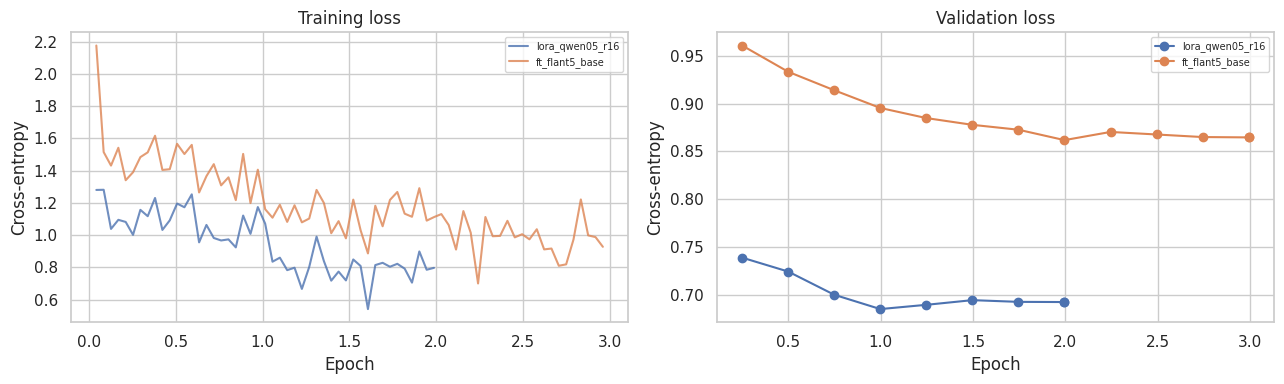

In [13]:
from afrimed.plots import load_all_metrics, results_table, plot_loss_curves
display(results_table(load_all_metrics()).round(4))
plot_loss_curves(["lora_qwen05_r16", "ft_flant5_base"]); plt.show()

The loss curves confirm this: Flan-T5's validation loss stays clearly higher than Qwen's during the whole training.

## Priority 2: ablations (rank, learning rate, target modules, data quality, RAG)

In the ablations I change one setting at a time from my main model: LoRA rank (8 and 32 instead of 16), a lower learning rate (5e-5 instead of 2e-4), LoRA only on the attention layers, and training only on clean rows. I also test RAG without fine-tuning, to separate the effect of retrieval from the effect of training.

In [14]:
_ = run_all(max_priority=2)

[skip] zs_qwen05 already evaluated
[skip] lora_qwen05_r16 already evaluated
[skip] ft_flant5_base already evaluated
[skip] lora_qwen05_r16_rag already evaluated
[run] lora_qwen05_r8: LoRA rank 8


Step,Training Loss,Validation Loss
59,1.083300,0.741264
118,1.098500,0.721599
177,0.988000,0.701997
236,1.174800,0.688076
295,0.739400,0.687605
354,0.781600,0.687045
413,0.891100,0.685018
472,0.875100,0.685398


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{
  "name": "lora_qwen05_r8",
  "group": "lora-rank",
  "description": "LoRA rank 8",
  "model_id": "Qwen/Qwen2.5-0.5B-Instruct",
  "method": "lora",
  "rag": false,
  "mcq_accuracy": 0.3820375335120643,
  "mcq_macro_f1": 0.37180275745466246,
  "mcq_ece": 0.08586721453845661,
  "mcq_n": 746,
  "mcq_multi_exact_match": 0.03225806451612903,
  "mcq_multi_jaccard": 0.4497311827956989,
  "mcq_multi_n": 62,
  "saq_rougeL": 0.30828940605407107,
  "saq_token_f1": 0.31742959817734345,
  "saq_semantic_sim": 0.6720542311668396,
  "saq_bertscore_f1": 0.2967354953289032,
  "saq_bleu": 13.313690667060634,
  "saq_chrf": 34.756873412191155,
  "saq_avg_pred_words": 31.434959349593495,
  "saq_avg_ref_words": 38.0650406504065,
  "saq_n": 246,
  "eval_time_sec": 63.422229290008545
}
[run] lora_qwen05_r32: LoRA rank 32


Step,Training Loss,Validation Loss
59,1.079900,0.743189
118,1.096100,0.719557
177,0.988700,0.706768
236,1.169500,0.687838
295,0.572200,0.695710
354,0.657200,0.701802
413,0.719100,0.695590
472,0.707600,0.695599


...

Step,Training Loss,Validation Loss
42,1.005900,0.610525
84,0.732000,0.582654
126,0.931100,0.565674
168,0.779100,0.557743
210,0.712000,0.570287
252,0.606700,0.555638
294,0.511600,0.555956
336,0.546600,0.555373


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{
  "name": "lora_qwen05_r16_clean",
  "group": "lora-data",
  "description": "LoRA r=16 trained only on quality-filtered rows (neg_percent <= 0.5, not flagged)",
  "model_id": "Qwen/Qwen2.5-0.5B-Instruct",
  "method": "lora",
  "rag": false,
  "mcq_accuracy": 0.3739946380697051,
  "mcq_macro_f1": 0.36035343505722195,
  "mcq_ece": 0.1281363994442426,
  "mcq_n": 746,
  "mcq_multi_exact_match": 0.016129032258064516,
  "mcq_multi_jaccard": 0.3776881720430107,
  "mcq_multi_n": 62,
  "saq_rougeL": 0.27615246644477487,
  "saq_token_f1": 0.28553792163825903,
  "saq_semantic_sim": 0.6662585735321045,
  "saq_bertscore_f1": 0.2553223967552185,
  "saq_bleu": 13.070736825303653,
  "saq_chrf": 33.73295814467354,
  "saq_avg_pred_words": 32.959349593495936,
  "saq_avg_ref_words": 38.0650406504065,
  "saq_n": 246,
  "eval_time_sec": 71.0381371974945
}
[run] zs_qwen05_rag: Zero-shot Qwen2.5-0.5B-Instruct + top-3 retrieved training QA pairs


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{
  "name": "zs_qwen05_rag",
  "group": "rag",
  "description": "Zero-shot Qwen2.5-0.5B-Instruct + top-3 retrieved training QA pairs",
  "model_id": "Qwen/Qwen2.5-0.5B-Instruct",
  "method": "none",
  "rag": true,
  "mcq_accuracy": 0.33646112600536193,
  "mcq_macro_f1": 0.31287456399540853,
  "mcq_ece": 0.19311832418870034,
  "mcq_n": 746,
  "mcq_multi_exact_match": 0.0,
  "mcq_multi_jaccard": 0.22876344086021505,
  "mcq_multi_n": 62,
  "saq_rougeL": 0.2146760977583982,
  "saq_token_f1": 0.23824396704188044,
  "saq_semantic_sim": 0.6971975564956665,
  "saq_bertscore_f1": 0.15507344901561737,
  "saq_bleu": 6.506948048128869,
  "saq_chrf": 35.199234062844646,
  "saq_avg_pred_words": 68.95934959349593,
  "saq_avg_ref_words": 38.0650406504065,
  "saq_n": 246,
  "eval_time_sec": 80.61474323272705
}


In [15]:
show_runs(["lora_qwen05_r8", "lora_qwen05_r32", "lora_qwen05_r16_lr5e5", "lora_qwen05_r16_attn", "lora_qwen05_r16_clean", "zs_qwen05_rag"])

### `lora_qwen05_r8`

trainable params: 4,399,104 of 498,431,872 (0.88%) | train examples: 3783 | training time: 8.9 min | final val loss: 0.6854


,training_loss,validation_loss
step,,
59,1.0833,0.7413
118,1.0985,0.7216
177,0.9880,0.7020
236,1.1748,0.6881
295,0.7394,0.6876
354,0.7816,0.6870
413,0.8911,0.6850
472,0.8751,0.6854


,mcq_accuracy,mcq_macro_f1,mcq_ece,mcq_multi_exact_match,mcq_multi_jaccard,saq_rougeL,saq_token_f1,saq_semantic_sim,saq_bertscore_f1,saq_bleu,saq_chrf,saq_avg_pred_words,saq_avg_ref_words
lora_qwen05_r8,0.382,0.3718,0.0859,0.0323,0.4497,0.3083,0.3174,0.6721,0.2967,13.3137,34.7569,31.435,38.065


### `lora_qwen05_r32`

...

,training_loss,validation_loss
step,,
42,1.0059,0.6105
84,0.7320,0.5827
126,0.9311,0.5657
168,0.7791,0.5577
210,0.7120,0.5703
252,0.6067,0.5556
294,0.5116,0.5560
336,0.5466,0.5554
340,0.6537,0.5553


,mcq_accuracy,mcq_macro_f1,mcq_ece,mcq_multi_exact_match,mcq_multi_jaccard,saq_rougeL,saq_token_f1,saq_semantic_sim,saq_bertscore_f1,saq_bleu,saq_chrf,saq_avg_pred_words,saq_avg_ref_words
lora_qwen05_r16_clean,0.374,0.3604,0.1281,0.0161,0.3777,0.2762,0.2855,0.6663,0.2553,13.0707,33.733,32.9593,38.065


### `zs_qwen05_rag`

no training (evaluated as-is)


,mcq_accuracy,mcq_macro_f1,mcq_ece,mcq_multi_exact_match,mcq_multi_jaccard,saq_rougeL,saq_token_f1,saq_semantic_sim,saq_bertscore_f1,saq_bleu,saq_chrf,saq_avg_pred_words,saq_avg_ref_words
zs_qwen05_rag,0.3365,0.3129,0.1931,0.0,0.2288,0.2147,0.2382,0.6972,0.1551,6.5069,35.1992,68.9593,38.065


**What I learned from the ablations:**

* **The settings matter less than fine-tuning itself.** All LoRA variants land between 37.3% and 38.6% MCQ accuracy, a much smaller spread than the 5-point gain from zero-shot to LoRA. With 746 test MCQs, differences of 1 point are within noise.
* **Rank 32 starts to overfit.** It reaches the lowest training loss, but its validation loss goes back up after the first epoch.
* **Attention-only LoRA is efficient.** It trains only 0.44% of the parameters and is as good on MCQs, but worse on SAQs (ROUGE-L 0.28 vs 0.31), so the MLP layers seem to help with writing answers.
* **The lower learning rate gives the best calibration** (ECE 0.045), but weaker short answers.
* **Clean data does not help.** Training only on clean rows (2,729 examples) gives the same MCQ accuracy and worse SAQs, so for this dataset more data beats a stricter filter. Its lower validation loss is not comparable, because the validation set is filtered too.
* **RAG without fine-tuning helps only a little** (33.6% vs 32.6%), so retrieval is most useful when the model has also been fine-tuned.

,name,group,mcq_accuracy,mcq_macro_f1,mcq_ece,mcq_multi_exact_match,mcq_multi_jaccard,saq_rougeL,saq_bleu,saq_chrf,saq_bertscore_f1,saq_semantic_sim,trainable_params,train_time_min,final_val_loss
9,lora_qwen05_r16_rag,rag,0.4035,0.3886,0.1003,0.0161,0.2720,0.3177,16.7821,38.7032,0.3140,0.6908,NaN,NaN,NaN
6,lora_qwen05_r16_attn,lora-modules,0.3861,0.3734,0.0520,0.0484,0.4226,0.2778,12.1576,33.9046,0.2732,0.6639,2162688.0,6.8063,0.6942
8,lora_qwen05_r16_lr5e5,lora-lr,0.3834,0.3696,0.0448,0.0323,0.4565,0.2727,11.1512,33.1847,0.2728,0.6610,8798208.0,8.9873,0.6933
11,lora_qwen05_r8,lora-rank,0.3820,0.3718,0.0859,0.0323,0.4497,0.3083,13.3137,34.7569,0.2967,0.6721,4399104.0,8.9165,0.6854
5,lora_qwen05_r16,lora,0.3740,0.3641,0.1343,0.0484,0.4272,0.3088,13.9537,35.0154,0.3012,0.6751,8798208.0,8.7852,0.6921
7,lora_qwen05_r16_clean,lora-data,0.3740,0.3604,0.1281,0.0161,0.3777,0.2762,13.0707,33.7330,0.2553,0.6663,8798208.0,6.4874,0.5553
10,lora_qwen05_r32,lora-rank,0.3727,0.3618,0.1733,0.0323,0.4220,0.3131,14.7894,36.0227,0.3060,0.6893,17596416.0,9.0077,0.6956
13,zs_qwen05_rag,rag,0.3365,0.3129,0.1931,0.0000,0.2288,0.2147,6.5069,35.1992,0.1551,0.6972,NaN,NaN,NaN
12,zs_qwen05,zero-shot,0.3257,0.3122,0.2741,0.0000,0.0425,0.1818,5.3169,35.3425,0.1160,0.6920,NaN,NaN,NaN
4,ft_flant5_base,full-ft,0.2882,0.2675,0.0235,0.0000,0.4043,0.2929,12.8855,29.3812,0.1972,0.6216,247577856.0,7.3746,0.8647


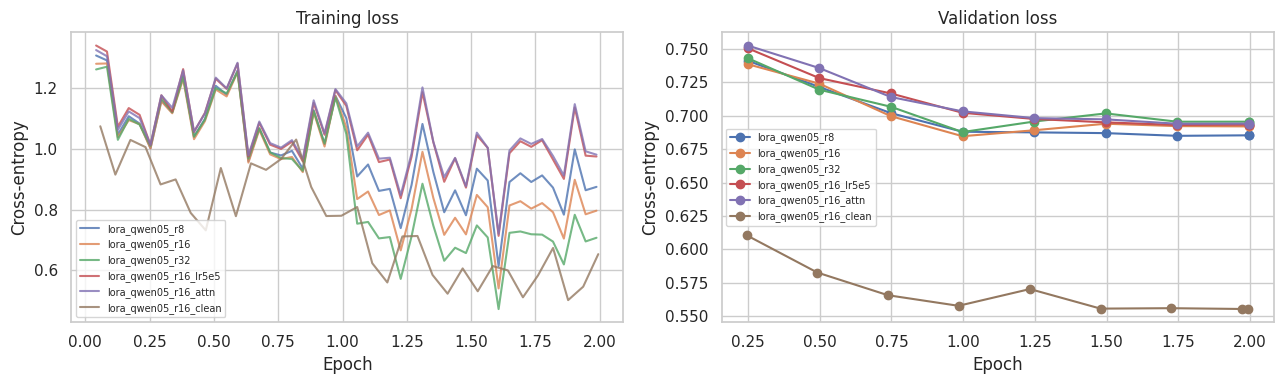

In [16]:
display(results_table(load_all_metrics()).round(4))
plot_loss_curves(["lora_qwen05_r8", "lora_qwen05_r16", "lora_qwen05_r32", "lora_qwen05_r16_lr5e5", "lora_qwen05_r16_attn", "lora_qwen05_r16_clean"]); plt.show()

## Priority 3: larger base model (Qwen2.5-1.5B)

Finally I check whether a larger base model helps. Qwen 1.5B has three times more parameters than the 0.5B model. I use gradient checkpointing to fit it in memory.

In [17]:
_ = run_all(max_priority=3)

[skip] zs_qwen05 already evaluated
[skip] lora_qwen05_r16 already evaluated
[skip] ft_flant5_base already evaluated
[skip] lora_qwen05_r16_rag already evaluated
[skip] lora_qwen05_r8 already evaluated
[skip] lora_qwen05_r32 already evaluated
[skip] lora_qwen05_r16_lr5e5 already evaluated
[skip] lora_qwen05_r16_attn already evaluated
[skip] lora_qwen05_r16_clean already evaluated
[skip] zs_qwen05_rag already evaluated
[run] zs_qwen15: Qwen2.5-1.5B-Instruct without fine-tuning


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{
  "name": "zs_qwen15",
  "group": "zero-shot",
  "description": "Qwen2.5-1.5B-Instruct without fine-tuning",
  "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
  "method": "none",
  "rag": false,
  "mcq_accuracy": 0.47319034852546915,
  "mcq_macro_f1": 0.46841530942625287,
  "mcq_ece": 0.3385365748772992,
  "mcq_n": 746,
  "mcq_multi_exact_match": 0.03225806451612903,
  "mcq_multi_jaccard": 0.20188172043010755,
  "mcq_multi_n": 62,
  "saq_rougeL": 0.18474974569614322,
  "saq_token_f1": 0.21399094554516018,
  "saq_semantic_sim": 0.7049310803413391,
  "saq_bertscore_f1": 0.13550430536270142,
  "saq_bleu": 4.978379015495489,
  "saq_chrf": 36.67116494440559,
  "saq_avg_pred_words": 81.72764227642277,
  "saq_avg_ref_words": 38.0650406504065,
  "saq_n": 246,
  "eval_time_sec": 175.61181831359863
}
[run] lora_qwen15_r16: Qwen2.5-1.5B-Instruct + LoRA r=16


`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Step,Training Loss,Validation Loss
59,0.907400,0.621145
118,0.923700,0.596518
177,0.803400,0.584805
236,0.966000,0.568798
295,0.508800,0.583030
354,0.594800,0.584888
413,0.645700,0.586512
472,0.647900,0.586153


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{
  "name": "lora_qwen15_r16",
  "group": "lora-scale",
  "description": "Qwen2.5-1.5B-Instruct + LoRA r=16",
  "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
  "method": "lora",
  "rag": false,
  "mcq_accuracy": 0.5455764075067024,
  "mcq_macro_f1": 0.5424812978552704,
  "mcq_ece": 0.136849998828553,
  "mcq_n": 746,
  "mcq_multi_exact_match": 0.06451612903225806,
  "mcq_multi_jaccard": 0.46424731182795703,
  "mcq_multi_n": 62,
  "saq_rougeL": 0.33165080129072577,
  "saq_token_f1": 0.34617548001584714,
  "saq_semantic_sim": 0.7096056938171387,
  "saq_bertscore_f1": 0.33882421255111694,
  "saq_bleu": 14.515442570425881,
  "saq_chrf": 37.32570029404975,
  "saq_avg_pred_words": 30.922764227642276,
  "saq_avg_ref_words": 38.0650406504065,
  "saq_n": 246,
  "eval_time_sec": 127.20543694496155
}
[run] lora_qwen15_r16_rag: Qwen2.5-1.5B LoRA r=16 + top-3 retrieved training QA pairs


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{
  "name": "lora_qwen15_r16_rag",
  "group": "rag",
  "description": "Qwen2.5-1.5B LoRA r=16 + top-3 retrieved training QA pairs",
  "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
  "method": "none",
  "rag": true,
  "mcq_accuracy": 0.5563002680965148,
  "mcq_macro_f1": 0.5542463837573111,
  "mcq_ece": 0.12768919845848237,
  "mcq_n": 746,
  "mcq_multi_exact_match": 0.016129032258064516,
  "mcq_multi_jaccard": 0.3841397849462366,
  "mcq_multi_n": 62,
  "saq_rougeL": 0.33664026848343687,
  "saq_token_f1": 0.3477468675386676,
  "saq_semantic_sim": 0.7160643935203552,
  "saq_bertscore_f1": 0.33805525302886963,
  "saq_bleu": 17.32047655221648,
  "saq_chrf": 40.451760436118704,
  "saq_avg_pred_words": 35.857723577235774,
  "saq_avg_ref_words": 38.0650406504065,
  "saq_n": 246,
  "eval_time_sec": 145.98140406608582
}


In [18]:
show_runs(["zs_qwen15", "lora_qwen15_r16", "lora_qwen15_r16_rag"])

### `zs_qwen15`

no training (evaluated as-is)


,mcq_accuracy,mcq_macro_f1,mcq_ece,mcq_multi_exact_match,mcq_multi_jaccard,saq_rougeL,saq_token_f1,saq_semantic_sim,saq_bertscore_f1,saq_bleu,saq_chrf,saq_avg_pred_words,saq_avg_ref_words
zs_qwen15,0.4732,0.4684,0.3385,0.0323,0.2019,0.1847,0.214,0.7049,0.1355,4.9784,36.6712,81.7276,38.065


### `lora_qwen15_r16`

trainable params: 18,464,768 of 1,562,179,072 (1.18%) | train examples: 3783 | training time: 13.8 min | final val loss: 0.5862


,training_loss,validation_loss
step,,
59,0.9074,0.6211
118,0.9237,0.5965
177,0.8034,0.5848
236,0.9660,0.5688
295,0.5088,0.5830
354,0.5948,0.5849
413,0.6457,0.5865
472,0.6479,0.5862


,mcq_accuracy,mcq_macro_f1,mcq_ece,mcq_multi_exact_match,mcq_multi_jaccard,saq_rougeL,saq_token_f1,saq_semantic_sim,saq_bertscore_f1,saq_bleu,saq_chrf,saq_avg_pred_words,saq_avg_ref_words
lora_qwen15_r16,0.5456,0.5425,0.1368,0.0645,0.4642,0.3317,0.3462,0.7096,0.3388,14.5154,37.3257,30.9228,38.065


### `lora_qwen15_r16_rag`

no training (evaluated as-is)


,mcq_accuracy,mcq_macro_f1,mcq_ece,mcq_multi_exact_match,mcq_multi_jaccard,saq_rougeL,saq_token_f1,saq_semantic_sim,saq_bertscore_f1,saq_bleu,saq_chrf,saq_avg_pred_words,saq_avg_ref_words
lora_qwen15_r16_rag,0.5563,0.5542,0.1277,0.0161,0.3841,0.3366,0.3477,0.7161,0.3381,17.3205,40.4518,35.8577,38.065


**What I learned from priority 3:**

* **Model size matters most.** The 1.5B model is already better zero-shot (47.3%) than any fine-tuned 0.5B model.
* **Fine-tuning still adds a lot.** LoRA raises it to 54.6%, and RAG to 55.6%, which is my best result. Its short answers are also the closest to the references (ROUGE-L 0.337, BERTScore 0.338).
* **RAG has a trade-off on multi-answer questions.** For the 1.5B model, RAG lowers multi-answer exact match from 6.5% to 1.6% and Jaccard from 0.46 to 0.38 (the same happens for 0.5B). The retrieved examples are mostly single-answer questions, which seems to push the model towards giving only one letter.

In [19]:
results_table(load_all_metrics()).round(4)

,name,group,mcq_accuracy,mcq_macro_f1,mcq_ece,mcq_multi_exact_match,mcq_multi_jaccard,saq_rougeL,saq_bleu,saq_chrf,saq_bertscore_f1,saq_semantic_sim,trainable_params,train_time_min,final_val_loss
13,lora_qwen15_r16_rag,rag,0.5563,0.5542,0.1277,0.0161,0.3841,0.3366,17.3205,40.4518,0.3381,0.7161,NaN,NaN,NaN
12,lora_qwen15_r16,lora-scale,0.5456,0.5425,0.1368,0.0645,0.4642,0.3317,14.5154,37.3257,0.3388,0.7096,18464768.0,13.8308,0.5862
16,zs_qwen15,zero-shot,0.4732,0.4684,0.3385,0.0323,0.2019,0.1847,4.9784,36.6712,0.1355,0.7049,NaN,NaN,NaN
9,lora_qwen05_r16_rag,rag,0.4035,0.3886,0.1003,0.0161,0.2720,0.3177,16.7821,38.7032,0.3140,0.6908,NaN,NaN,NaN
6,lora_qwen05_r16_attn,lora-modules,0.3861,0.3734,0.0520,0.0484,0.4226,0.2778,12.1576,33.9046,0.2732,0.6639,2162688.0,6.8063,0.6942
8,lora_qwen05_r16_lr5e5,lora-lr,0.3834,0.3696,0.0448,0.0323,0.4565,0.2727,11.1512,33.1847,0.2728,0.6610,8798208.0,8.9873,0.6933
11,lora_qwen05_r8,lora-rank,0.3820,0.3718,0.0859,0.0323,0.4497,0.3083,13.3137,34.7569,0.2967,0.6721,4399104.0,8.9165,0.6854
7,lora_qwen05_r16_clean,lora-data,0.3740,0.3604,0.1281,0.0161,0.3777,0.2762,13.0707,33.7330,0.2553,0.6663,8798208.0,6.4874,0.5553
5,lora_qwen05_r16,lora,0.3740,0.3641,0.1343,0.0484,0.4272,0.3088,13.9537,35.0154,0.3012,0.6751,8798208.0,8.7852,0.6921
10,lora_qwen05_r32,lora-rank,0.3727,0.3618,0.1733,0.0323,0.4220,0.3131,14.7894,36.0227,0.3060,0.6893,17596416.0,9.0077,0.6956


## Publish the best model to the Hugging Face Hub

I merge the best model with its LoRA adapter and upload it to the Hugging Face Hub. My web app downloads it from there, together with the retrieval index and the domain gate.

In [ ]:
BEST = "lora_qwen05_r16"
HUB_REPO = "mukunzindahiro-max/afrimed-assistant-qwen2.5-0.5b-lora"
!python scripts/push_to_hub.py --experiment $BEST --repo $HUB_REPO

## Download results to commit to GitHub

I zip all results and figures, download them, and add them to my GitHub repository so notebook 04 and the report can use them.

In [21]:
!cd /content && zip -qr afrimed_results.zip afrimed-assistant/results afrimed-assistant/reports/figures -x '*.ipynb_checkpoints*'
from google.colab import files
files.download("/content/afrimed_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>